# Model analysis

Phase 4 of *Finner jeg en bysykkel?*. Looks inside the final models
(`uv run python -m ml.run_model`, saved in `models/`) on the **test week**
(23–30 October): the MAE model for the expected number of bikes, and the
classifier for P(at least one bike). The test week was scored once in
`results/model.md` and `results/probability.md`; this notebook only explains
those results and changes nothing.

1. Which features the MAE model uses
2. Error by hour of day compared with `unchanged`
3. One station over one day, with the expected number and the probability

In [1]:
import os
import sys
from pathlib import Path

# Run from the repository root, so `ml` imports and `data/` resolves.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import pandas as pd

from ml.baselines import Unchanged
from ml.features import add_features
from ml.grid import OSLO, load_stations, load_status, to_grid
from ml.model import MODEL_DIR, load, load_classifiers, predict
from ml.pairs import make_pairs, split
from ml.probability import predict_proba

grid = to_grid(load_status())
stations = load_stations()
booster, meta = load()
classifiers = load_classifiers(MODEL_DIR, meta)
_, test = split(make_pairs(grid, stations))
test = add_features(
    test, grid, stations=meta["stations"], neighbours=meta["neighbours"]
)
test["unchanged"] = Unchanged().predict(test)
test["lightgbm"] = predict(booster, test)
test["p_bike"] = predict_proba(classifiers["bike"], test)
for model in ["unchanged", "lightgbm"]:
    test[f"error_{model}"] = (test[model] - test["target_bikes"]).abs()
test["local"] = test["slot"].dt.tz_convert(OSLO)
print(
    f"{len(test)} test pairs, {test['station_id'].nunique()} stations, {booster.num_trees()} trees"
)

535215 test pairs, 266 stations, 160 trees


## 1. Feature importance

*Gain* is how much each feature reduced the training loss, summed over all
splits that use it. It shows what the model relies on, not cause and effect,
and correlated features share the credit.

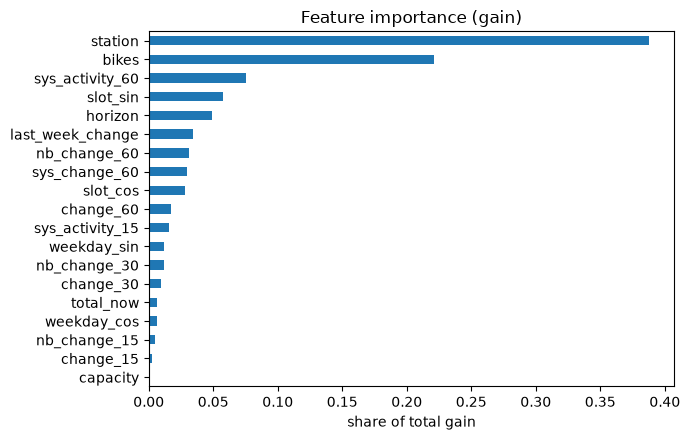

,gain share,splits
station,0.388,14520
bikes,0.221,3152
sys_activity_60,0.075,3261
slot_sin,0.057,2601
horizon,0.049,2243
last_week_change,0.034,1742
nb_change_60,0.031,1872
sys_change_60,0.030,2153
slot_cos,0.028,1723
change_60,0.017,1412


In [2]:
gain = pd.Series(
    booster.feature_importance("gain"), index=booster.feature_name()
).sort_values()
splits = pd.Series(booster.feature_importance("split"), index=booster.feature_name())
share = (gain / gain.sum()).rename("gain share")

fig, ax = plt.subplots(figsize=(7, 4.5))
share.plot.barh(ax=ax, color="tab:blue")
ax.set_xlabel("share of total gain")
ax.set_title("Feature importance (gain)")
fig.tight_layout()
plt.show()

pd.DataFrame({"gain share": share, "splits": splits}).sort_values(
    "gain share", ascending=False
).round(3)

## 2. Error by hour of day

Weekdays only, by local hour at the origin. The model should gain most where
bikes actually move: the morning and afternoon rush.

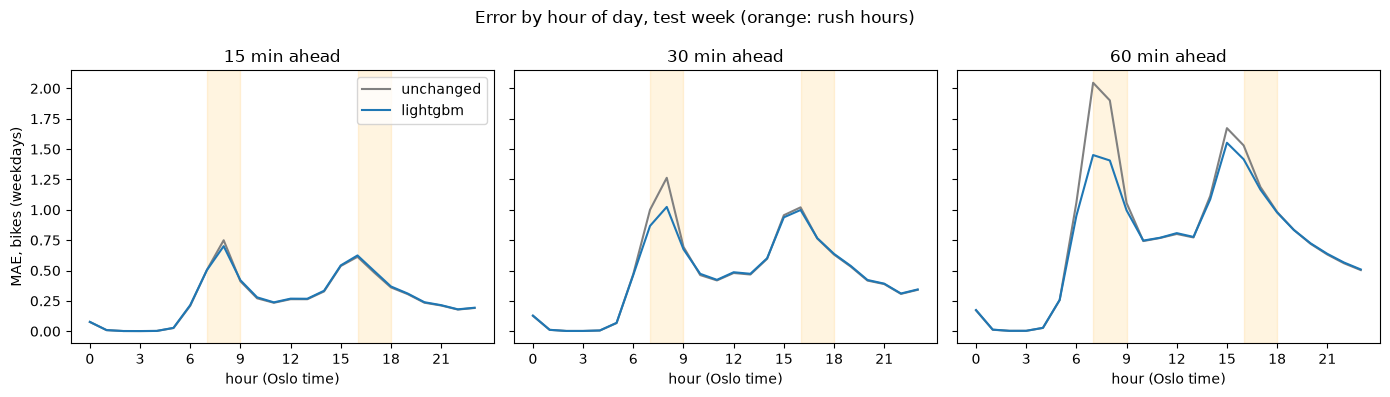

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
gain at 60 min,-0.02,-0.11,-0.07,-0.11,-0.02,-0.01,0.1,0.29,0.26,0.06,...,0.03,0.07,0.07,0.02,0.0,0.0,-0.01,-0.01,-0.01,-0.01


In [3]:
weekdays = test[test["weekday"] < 5]
by_hour = weekdays.groupby(["horizon", "hour"])[
    ["error_unchanged", "error_lightgbm"]
].mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, horizon in zip(axes, [15, 30, 60], strict=True):
    h = by_hour.loc[horizon]
    ax.plot(h.index, h["error_unchanged"], label="unchanged", color="grey")
    ax.plot(h.index, h["error_lightgbm"], label="lightgbm", color="tab:blue")
    for start, end in [(7, 9), (16, 18)]:
        ax.axvspan(start, end, color="orange", alpha=0.12)
    ax.set_title(f"{horizon} min ahead")
    ax.set_xlabel("hour (Oslo time)")
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel("MAE, bikes (weekdays)")
axes[0].legend()
fig.suptitle("Error by hour of day, test week (orange: rush hours)")
fig.tight_layout()
plt.show()

gain_60 = 1 - by_hour.loc[60, "error_lightgbm"] / by_hour.loc[60, "error_unchanged"]
gain_60.rename("gain at 60 min").to_frame().T.round(2)

## 3. One station over one day

The station with the largest weekday-rush error for `unchanged` on Tuesday
27 October. Each forecast is drawn at the time it is *for* (the target), so it
can be compared directly with what happened. The lower panel is what a user
would see: the probability, made 60 minutes earlier, that there is at least one
bike, with the slots where the station actually was empty shaded.

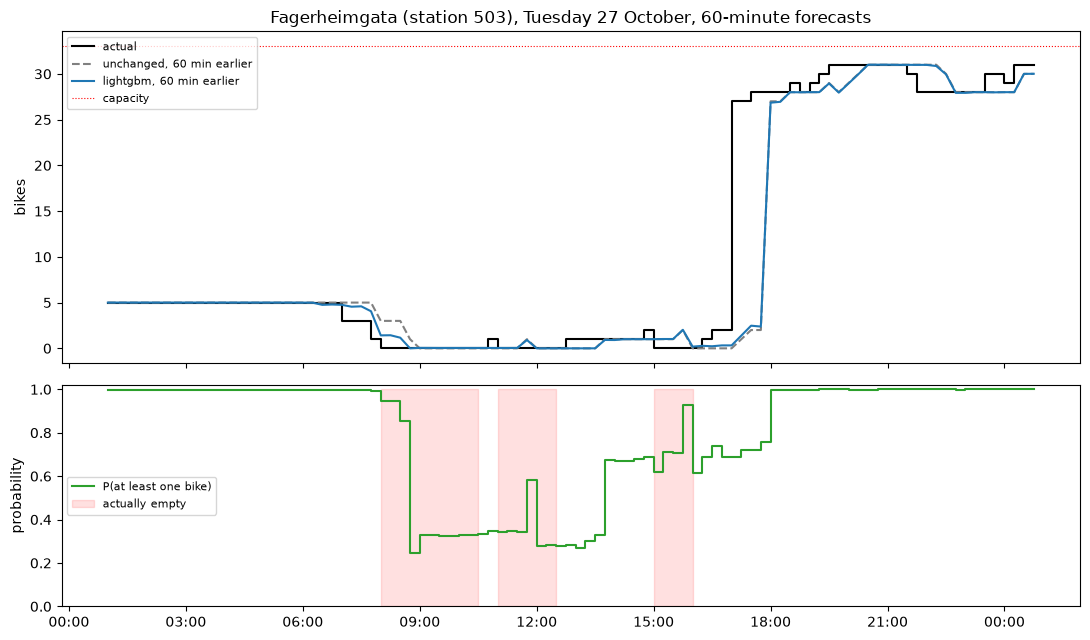

MAE this day, 60 min: unchanged 1.85, lightgbm 1.76
Mean P(at least one bike) when empty: 0.49, when not empty: 0.90


In [4]:
day = pd.Timestamp("2026-10-27", tz=OSLO)
same_day = test[(test["local"] >= day) & (test["local"] < day + pd.Timedelta(days=1))]
rush = same_day[same_day["hour"].isin([7, 8, 16, 17]) & (same_day["horizon"] == 60)]
station = rush.groupby("station_id")["error_unchanged"].mean().idxmax()
name = stations.set_index("station_id").loc[station, "name"]

s = same_day[(same_day["station_id"] == station) & (same_day["horizon"] == 60)]
target_local = s["target_slot"].dt.tz_convert(OSLO)

fig, (ax, ax_p) = plt.subplots(
    2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
ax.step(target_local, s["target_bikes"], where="post", color="black", label="actual")
ax.plot(
    target_local,
    s["unchanged"],
    color="grey",
    ls="--",
    label="unchanged, 60 min earlier",
)
ax.plot(target_local, s["lightgbm"], color="tab:blue", label="lightgbm, 60 min earlier")
ax.axhline(s["capacity"].iloc[0], color="red", lw=0.8, ls=":", label="capacity")
ax.set_ylabel("bikes")
ax.set_title(f"{name} (station {station}), Tuesday 27 October, 60-minute forecasts")
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=OSLO))
ax.legend(loc="upper left", fontsize=8)

empty = s["target_bikes"] == 0
ax_p.step(
    target_local,
    s["p_bike"],
    where="post",
    color="tab:green",
    label="P(at least one bike)",
)
ax_p.fill_between(
    target_local,
    0,
    1,
    where=empty,
    step="post",
    color="red",
    alpha=0.12,
    label="actually empty",
)
ax_p.set_ylim(0, 1.02)
ax_p.set_ylabel("probability")
ax_p.legend(loc="center left", fontsize=8)
ax_p.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=OSLO))
fig.tight_layout()
plt.show()

print(
    f"MAE this day, 60 min: unchanged {s['error_unchanged'].mean():.2f}, "
    f"lightgbm {s['error_lightgbm'].mean():.2f}"
)
print(
    f"Mean P(at least one bike) when empty: {s.loc[empty, 'p_bike'].mean():.2f}, "
    f"when not empty: {s.loc[~empty, 'p_bike'].mean():.2f}"
)

## Findings

- **Station ID carries 39 % of the gain and current bikes 22 %.** City-wide
  activity in the last hour (`sys_activity_60`, 8 %) is now the third most
  used feature, ahead of time of day. The neighbour features add about 5 %
  together. The model has learned *which station behaves how*, adjusted by how
  full it is and how busy the city is right now.
- **The gain is concentrated in the morning rush.** At 60 minutes the error at
  07–09 on weekdays drops by more than a quarter (07: +29 %, 08: +26 %). The
  afternoon rush improves much less (16: +7 %, 17: +2 %): evening returns are
  spread over more stations and times. At night the model is slightly worse,
  but those errors are tiny in absolute terms.
- **The example station shows strengths and limits.** In the morning the
  expected number falls before the station empties, earlier than `unchanged`.
  The probability tells the user more: it drops from 95 % to 25–35 % while the
  station is empty and climbs again in the afternoon. On average it was 49 %
  in slots that turned out empty and 90 % in the others. The very first empty
  slot (08:00) was still forecast at 95 % an hour earlier, so the model reacts
  to an emptying station rather than foreseeing it.
- **Redistribution trucks remain out of reach.** At 17:00 the station suddenly
  gets about 25 bikes. No feature can see that coming, and both models are
  wrong by the same amount for an hour.
